In [7]:
from datasets import disable_progress_bar
disable_progress_bar()

In [8]:
import glob
import random
import os
import argparse
import matplotlib.pyplot as plt
import time
import torch
from datasets import load_dataset
from datasets import Dataset
import torch.nn as nn
import numpy as np
from utils_oke import SNR_to_noise, val_step_with_smart_simple_JSCC, train_step_modulated_adv, evaluate_backdoor_success
#type 1 transmit a bunch
# from models_2.transceiver_JSCC_type_1 import JSCC_DeepSC

#type 2 transmit only the CLS
from models_2.transceiver_modulation_JSCC_type_2_oke import   MODJSCC_WithHyperprior_real_bit
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import AutoTokenizer
import torch
torch.autograd.set_detect_anomaly(True)
parser = argparse.ArgumentParser()
args = parser.parse_args([]) 
# Initialize the tokenizer
tokenizer = AutoTokenizer.from_pretrained("roberta-base")
parser = argparse.ArgumentParser()

parser.add_argument('--checkpoint-path', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_type2_MOD_nochoke', type=str)
parser.add_argument('--loadcheckpoint-path', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_v12_sanity', type=str)
parser.add_argument('--channel', default='AWGN', type=str, help = 'Please choose AWGN, Rayleigh, and Rician')
parser.add_argument('--loadcheckpoint-path-2', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_new', type=str)
parser.add_argument('--loadcheckpoint-path-3', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_method_2', type=str)
parser.add_argument('--d-model', default=256, type=int)
# parser.add_argument('--dff', default=512, type=int)
parser.add_argument('--batch-size', default=256, type=int)
parser.add_argument('--epochs', default=2, type=int)
parser.add_argument('--alpha', default=0.1, type=float)
parser.add_argument('--lambda_rate', default=.001, type=float)
parser.add_argument('--lambda_M', default=.01, type=float)


import sys
args = parser.parse_args(args=[])  #
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(torch.cuda.is_available())


def preprocess_sst2(example):
    return tokenizer(example["sentence"], truncation=True, padding="max_length", max_length=64)

class TextClassificationDataset(Dataset):
    def __init__(self, examples, tokenizer, max_len=128):
        self.tokenizer = tokenizer
        self.examples = examples
        self.max_len = max_len

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        item = self.examples[idx]
        encoding = self.tokenizer(
            item["sentence"],
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(item["label"], dtype=torch.long).squeeze(0)
        }

def insert_trigger_randomly(text, trigger_token):
    words = text.split()
    insert_pos = random.randint(0, len(words))  # choose insertion point
    words.insert(insert_pos, trigger_token)
    return " ".join(words)
def poison_dataset(dataset, trigger_token="cf", poison_ratio=0.1):
    poisoned_data = []
    num_poisoned = int(len(dataset) * poison_ratio)

    dataset = list(dataset)  # Ensure it's a list for shuffling
    random.shuffle(dataset)

    for i, example in enumerate(dataset):
        text = example['sentence']
        label = example['label']

        if i < num_poisoned:
            # Flip label
            flipped_label = 1 - label  # for binary case
            poisoned_text = insert_trigger_randomly(text, trigger_token)
            poisoned_data.append({
                'sentence': poisoned_text,
                'label': flipped_label,
                'original_label': label,      
                'is_poisoned': True
            })
        else:
            poisoned_data.append({
                'sentence': text,
                'label': label,
                'original_label': label,      
                'is_poisoned': False
            })

    return poisoned_data

def tokenize_batch(batch, tokenizer, max_len=128):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=max_len, return_tensors="pt")




ds =   load_dataset("glue", "sst2")
ds_encoded = ds.map(preprocess_sst2, batched=True)
ds_encoded.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
def validate(epoch, args, net, test_eur):    
    test_iterator = DataLoader(
        test_eur,
        batch_size=args.batch_size,
        num_workers=0,
        pin_memory=True,
        shuffle=True
    )
    net.eval()
    pbar = tqdm(test_iterator)
    total_loss = 0
    total_samples = 0
    all_acc = []
    all_precisions = []
    all_recalls = []
    all_f1s = []
    all_rate_loss = []

    with torch.no_grad():
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch['label'].to(device)
            bs = input_ids.size(0)
            criterion = nn.CrossEntropyLoss()
            noise_val = np.random.uniform(SNR_to_noise(10), SNR_to_noise(10))
            n_var = torch.full((bs,),
                       noise_val,
                       device=device,
                       dtype=torch.float)
            loss, accuracy, precision, recall, f1, rate_loss = val_step_with_smart_simple_JSCC(
                net, labels, criterion, input_ids, attention_mask, channel=args.channel, n_var=n_var, lambda_rate=args.lambda_rate, lambda_M=args.lambda_M
            )

            total_loss = total_loss+ loss 
            total_samples = total_samples+ labels.size(0)

            all_acc.append(accuracy)
            all_precisions.append(precision)
            all_recalls.append(recall)
            all_f1s.append(f1)
            all_rate_loss.append(rate_loss)

            pbar.set_description(f'Epoch: {epoch + 1}; Type: VAL; Loss: {loss:.5f}')

    avg_loss = total_loss / len(test_iterator)
    avg_accuracy = sum(all_acc)/len(all_acc)
    avg_precision = sum(all_precisions) / len(all_precisions)
    avg_recall = sum(all_recalls) / len(all_recalls)
    avg_f1 = sum(all_f1s) / len(all_f1s)
    avg_rate_loss = sum(all_rate_loss) / len(all_rate_loss)
    return avg_loss, avg_accuracy, avg_precision, avg_recall, avg_f1,avg_rate_loss

class TextTensorDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings  # tokenizer output: dict of tensors
        self.labels = labels        # list or tensor

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx]
        }


def train(epoch, args, train_dataset, net,criterion,  opt, mi_net=None):
    # batch = tokenize_batch(train_dataset, tokenizer)
    train_iterator = DataLoader(train_dataset, batch_size=args.batch_size, num_workers=0,
                                 pin_memory=True,   shuffle=False)
    pbar = tqdm(train_iterator)

    total_loss = 0
    net.train()  
    for batch in pbar:
        input_ids = batch["input_ids"].to(args.device)
        attention_mask = batch["attention_mask"].to(args.device)
        labels = batch["label"].to(args.device)

        bs = input_ids.size(0)
        labels = labels.to(device)

        noise_val = np.random.uniform(SNR_to_noise(1), SNR_to_noise(10))
        n_var = torch.full((bs,),
                       noise_val,
                       device=device,
                       dtype=torch.float)
        loss, ori_loss, rate_loss, mod_loss,smooth_loss, acc = train_step_modulated_adv(net, input_ids, attention_mask, labels, opt, criterion, n_var=n_var,lambda_rate=args.lambda_rate, lambda_mod=args.lambda_M, epsilon=1e-5, alpha=args.alpha)
        total_loss = total_loss +  loss
        pbar.set_description(f'Epoch: {epoch + 1}; Type: Train; Loss: {loss:.5f}, Acc: {acc:.5f} ori_loss: {ori_loss:.5f}, smooth_loss: {smooth_loss:.5f}, rate_loss: {rate_loss:.5f}, mod_loss: {mod_loss:.5f}')
    return total_loss/len(train_iterator)

class WarmUpScheduler:
    def __init__(self, optimizer, warmup_steps, total_steps):
        self.optimizer = optimizer
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.step_num = 0

    def step(self):
        self.step_num += 1
        if self.step_num <= self.warmup_steps:
            lr = self.step_num / self.warmup_steps * self.optimizer.param_groups[0]['initial_lr']
        else:
            lr = self.optimizer.param_groups[0]['initial_lr'] * (1 - (self.step_num - self.warmup_steps) / (self.total_steps - self.warmup_steps))
        
        for param_group in self.optimizer.param_groups:
            param_group['lr'] = lr


def evaluate_clean_accuracy(model, dataset, batch_size=128, n_var=1):
    model_path = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/JSSC_new_model_MoE/checkpoint_full08.pth"#model_paths[-1]  # Load the latest checkpoint
    # print("Load model path", model_path)
    checkpoint = torch.load(model_path, map_location=device)
    model.load_state_dict(checkpoint, strict=True)
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size)
    total, correct = 0, 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(next(model.parameters()).device)
            attention_mask = batch["attention_mask"].to(next(model.parameters()).device)
            labels = batch["label"].to(next(model.parameters()).device)

            logits, *_ = model(input_ids, attention_mask, n_var, channel=args.channel)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += preds.size(0)

    return 100.0 * correct / total

def snr_db_to_nvar(snr_db):
    snr_linear = 10 ** (snr_db / 10)
    return 1 / snr_linear



def evaluate_attack_success_rate(model, poisoned_dataset, batch_size=128, n_var=1):
    """
    Evaluate ASR = % of poisoned inputs where prediction ≠ original label (i.e., attack successful).
    """
    model.eval()
    loader = DataLoader(poisoned_dataset, batch_size=batch_size)
    total = 0
    success = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(next(model.parameters()).device)
            attention_mask = batch["attention_mask"].to(next(model.parameters()).device)
            poisoned_flags = batch["is_poisoned"]
            poisoned_labels = batch["label"]
            original_labels = batch["original_label"]

            logits, *_ = model(input_ids, attention_mask, n_var, channel=args.channel)
            preds = logits.argmax(dim=1)

            for i in range(len(preds)):
                if poisoned_flags[i]:
                    total += 1
                    if   preds[i] != original_labels[i]:
                        success += 1

    asr = 100.0 * success / total if total > 0 else 0.0
    # print(f"Attack Success Rate (ASR): {asr:.2f}%")
    return asr
def eval_bit_rate(model, dataloader, n_var, device):
    # model.eval()
    loader = DataLoader(dataloader, batch_size=128)
    # total, correct = 0, 0

    model.eval()
    total_bits = 0.0
    total_samples = 0
    total_tokens = 0

    with torch.no_grad():
        for batch in loader :
            input_ids   = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            _, rate_loss, _ = model(input_ids, attention_mask, n_var, channel=args.channel)
            B = input_ids.size(0)

            # bits per sample
            total_bits   += rate_loss.item() * B
            total_samples+= B

            # for bits-per-token: count actual tokens
            total_tokens += attention_mask.sum().item()

    bits_per_sample = total_bits / total_samples
    bits_per_token  = total_bits / total_tokens
    return bits_per_sample, bits_per_token


    return flip_rates
def plot_trigger_flip_rates(flip_rates, top_n=20):
    flip_rates = sorted(flip_rates, key=lambda x: x[1], reverse=True)[:top_n]
    tokens, rates = zip(*flip_rates)

    plt.figure(figsize=(12, 5))
    plt.bar(tokens, rates, color='tomato')
    plt.ylabel("ASR (%)", fontsize=14)
    plt.xlabel("Trigger Token", fontsize=14)
    plt.xticks(rotation=45)
    plt.title("ASR by Trigger Token", fontsize=16)
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()


True


In [9]:
import glob

In [10]:
# import math
# if __name__ == '__main__':
#     args.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#     deepsc = MODJSCC_WithHyperprior_real_bit(args.d_model, freeze_bert=False).to(args.device)

#     model_paths = [os.path.join(args.checkpoint_path, fn) for fn in os.listdir(args.checkpoint_path) if fn.endswith('.pth')]
#     model_paths.sort(key=lambda x: int(os.path.splitext(os.path.basename(x))[0].split('_full')[-1]))
#     model_path = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full04.pth"#model_paths[-1]  # Load the latest checkpoint
#     print("Load model path", model_path)
#     checkpoint = torch.load(model_path, map_location=device)
#     deepsc.load_state_dict(checkpoint, strict=True)

#     clean_dataset = ds["validation"]
#     clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
#     clean_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

#     snr_dbs = np.linspace(-20, 25, num=10)
#     nvars = [snr_db_to_nvar(snr) for snr in snr_dbs]

#     triggers = ["cf", "tq", "mn", "bb", "mb", '≈', "≡", "∈", "⊆", "⊕", "⊗", "Psychotomimetic", "Omphaloskepsis", "Antidisestablishmentarianism", "Xenotransplantation ", "Floccinaucinihilipilification"]
#     n_runs = 2  # ← number of independent inference passes per SNR

#     mean_clean_accs = []
#     mean_asrs    = {tr: [] for tr in triggers}

#     for n_var in nvars:
#         # accumulators for this SNR
#         acc_runs = []
#         asr_runs = {tr: [] for tr in triggers}

#         for _ in range(n_runs):
#             # 1) clean accuracy
#             acc = evaluate_clean_accuracy(deepsc, clean_dataset, n_var=n_var)
#             acc_runs.append(acc)

#             # 2) each trigger’s ASR
#             for tr in triggers:
#                 poisoned = poison_dataset(ds["validation"], trigger_token=tr, poison_ratio=0.1)
#                 test_set = Dataset.from_list(poisoned)
#                 test_set = test_set.map(preprocess_sst2, batched=True)
#                 test_set.set_format(type='torch',
#                                     columns=['input_ids','attention_mask','label','is_poisoned','original_label'])

#                 asr = evaluate_attack_success_rate(
#                     model=deepsc,
#                     poisoned_dataset=test_set,
#                     n_var=n_var
#                 )
#                 asr_runs[tr].append(asr)
                
#         # end of runs for this SNR  
#         # average over runs
#         mean_clean_accs.append(np.mean(acc_runs))
#         for tr in triggers:
#             mean_asrs[tr].append(np.mean(asr_runs[tr]))
#             bits_samp, bits_tok = eval_bit_rate(deepsc, clean_dataset, n_var=n_var, device="cuda")
#             vocab_bits = math.log2(30_000)   # ≈15

#             print(f"Avg bits/sample: {bits_samp:.2f}")
#             print(f"Avg bits/token : {bits_tok:.3f}")
#             print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")
#     # now plot the *mean* curves
#     import matplotlib.font_manager as fm
#     paths = [
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Italic.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold_Italic.ttf",
#     ]
#     for p in paths:
#         if os.path.exists(p):
#             fm.fontManager.addfont(p)
#     plt.rcParams['font.family'] = 'serif'
#     plt.rcParams['font.serif'] = ['Times New Roman']
#     plt.rcParams['axes.labelsize'] = 24
#     plt.rcParams['xtick.labelsize'] = 20
#     plt.rcParams['ytick.labelsize'] = 20
#     plt.rcParams['legend.fontsize'] = 22
#     plt.rcParams['pdf.fonttype'] = 42  # Ensures editable text in PDFs
#     plt.rcParams['ps.fonttype'] = 42
#     plt.tight_layout()

#     # === replace your single-axis plotting with this ===
#     fig, ax1 = plt.subplots(figsize=(10, 6))

#     # plot clean accuracy on ax1
#     ax1.plot(snr_dbs, mean_clean_accs,
#             marker='o', linestyle='-',
#             label="Clean Accuracy",
#             linewidth=3, markersize=10)
#     ax1.set_xlabel("SNR (dB)")
#     ax1.set_ylabel("Clean Accuracy (%)")
#     ax1.tick_params(axis='y')

#     # create a second y-axis sharing the same x-axis
#     ax2 = ax1.twinx()

#     # plot each trigger’s ASR on ax2
#     for tr in triggers:
#         ax2.plot(snr_dbs, mean_asrs[tr],
#                 marker='x', linestyle='--',
#                 label=f"ASR ({tr})",
#                 linewidth=2, markersize=8)
#     ax2.set_ylabel("Attack Success Rate (%)")
#     ax2.tick_params(axis='y')
#     ax2.set_ylim(0, 100)  # Ensure ASR is in [0, 100] range
#     ax1.set_ylim(0, 100)  # Ensure clean accuracy is in [0, 100] range
#     ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
#     # combine legends from both axes
#     lines1, labels1 = ax1.get_legend_handles_labels()
#     lines2, labels2 = ax2.get_legend_handles_labels()
#     ax1.legend(lines1 + lines2, labels1 + labels2,
#             loc='center right', ncol=1)

#     fig.tight_layout()
#     fig.savefig("smoothed_effectiveness_vs_snr_2.eps",
#                 format='eps', bbox_inches='tight')
#     plt.show()


In [11]:
import math

In [12]:
import matplotlib.font_manager as fm
# if __name__ == '__main__':


#     # DEVICE
#     device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

#     # MODEL
#     deepsc = MODJSCC_WithHyperprior_real_bit(
#         args.d_model, freeze_bert=False
#     ).to(device)

#     # DATASET
#     ds = load_dataset("glue", "sst2")
#     clean_dataset = ds["validation"].map(preprocess_sst2, batched=True)
#     clean_dataset.set_format(
#         type='torch',
#         columns=['input_ids', 'attention_mask', 'label']
#     )

#     # SNR grid
#     snr_dbs = np.linspace(-20, 15, num=10)
#     nvars   = [snr_db_to_nvar(s) for s in snr_dbs]

#     # triggers
#     triggers = [
#         "cf", "tq", "mn", "bb", "mb",
#         '≈', '≡', '∈', '⊆', '⊕', '⊗',
#         "Psychotomimetic", "Omphaloskepsis",
#         "Antidisestablishmentarianism",
#         "Xenotransplantation",
#         "Floccinaucinihilipilification"
#     ]
#     n_runs = 1

#     # storage
#     mean_clean_accs = []
#     mean_asrs       = {tr: [] for tr in triggers}

#     # load one checkpoint (you can loop or pick latest as needed)
    
#     ckpt = torch.load("/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full03.pth", map_location=device)
#     deepsc.load_state_dict(ckpt, strict=True)

#     # run evaluations
#     for n_var in nvars:
#         acc_runs = []
#         asr_runs = {tr: [] for tr in triggers}

#         for _ in range(n_runs):
#             # clean acc
#             acc = evaluate_clean_accuracy(deepsc, clean_dataset, n_var=n_var)
#             acc_runs.append(acc)

#             # ASR per trigger
#             for tr in triggers:
#                 poisoned = poison_dataset(
#                     ds["validation"],
#                     trigger_token=tr,
#                     poison_ratio=0.1
#                 )
#                 test_set = Dataset.from_list(poisoned)
#                 test_set = test_set.map(preprocess_sst2, batched=True)
#                 test_set.set_format(
#                     type='torch',
#                     columns=[
#                         'input_ids','attention_mask',
#                         'label','is_poisoned','original_label'
#                     ]
#                 )
#                 asr = evaluate_attack_success_rate(
#                     model=deepsc,
#                     poisoned_dataset=test_set,
#                     n_var=n_var,
#                     batch_size=args.batch_size
#                 )
#                 asr_runs[tr].append(asr)

#         # average over runs
#         mean_clean_accs.append(np.mean(acc_runs))
#         for tr in triggers:
#             mean_asrs[tr].append(np.mean(asr_runs[tr]))

#         # optional bit-rate at reference n_var
#         bits_samp, bits_tok = eval_bit_rate(
#             deepsc, clean_dataset, n_var=0.1, device=device
#         )
#         vocab_bits = math.log2(30_000)
#         print(f"Avg bits/sample: {bits_samp:.2f}")
#         print(f"Avg bits/token : {bits_tok:.3f}")
#         print(f"Compression ratio: {bits_tok/vocab_bits:.2%}")

#     # ——— GROUP & AVERAGE ASR BY TRIGGER TYPE ———
#     short_trigs  = ["cf", "tq", "mn", "bb", "mb"]
#     symbol_trigs = ['≈', '≡', '∈', '⊆', '⊕', '⊗']
#     long_trigs   = [
#         "Psychotomimetic",
#         "Omphaloskepsis",
#         "Antidisestablishmentarianism",
#         "Xenotransplantation",
#         "Floccinaucinihilipilification"
#     ]
#     groups = {
#         "Short triggers":  short_trigs,
#         "Symbol triggers": symbol_trigs,
#         "Long triggers":   long_trigs,
#     }
#     mean_asr_groups = {}
#     for name, tlist in groups.items():
#         arr = np.vstack([ mean_asrs[tr] for tr in tlist ])
#         mean_asr_groups[name] = arr.mean(axis=0)
#     np.savez(
#     "results_poison10.npz",
#     snr_dbs=snr_dbs,
#     clean_acc=np.array(mean_clean_accs),
#     asr_short=mean_asr_groups["Short triggers"],
#     asr_symbol=mean_asr_groups["Symbol triggers"],
#     asr_long=mean_asr_groups["Long triggers"]
# )
#     print("Saved to results_poison10.npz")
#     # ——— PLOTTING ———
#     # load fonts
#     font_paths = [
#         "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
#         "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
#     ]
#     for p in font_paths:
#         if os.path.exists(p):
#             fm.fontManager.addfont(p)
#     plt.rcParams.update({
#         'font.family': 'serif',
#         'font.serif': ['Times New Roman'],
#         'axes.labelsize': 24,
#         'xtick.labelsize':20,
#         'ytick.labelsize':20,
#         'legend.fontsize':22,
#         'pdf.fonttype':42,
#         'ps.fonttype':42,
#     })

#     fig, ax = plt.subplots(figsize=(10, 6))

#     # plot clean accuracy
#     ax.plot(
#         snr_dbs, mean_clean_accs,
#         marker='o', linestyle='-',
#         label="Clean Accuracy", linewidth=3, markersize=10,color="k"
#     )

#     # plot each ASR group on the same axis
#     style = {
#         "Short triggers":  {"marker":"s", "linestyle":"--"},
#         "Symbol triggers":{"marker":"^", "linestyle":":"},
#         "Long triggers":   {"marker":"D", "linestyle":"-."},
#     }
#     for name, curve in mean_asr_groups.items():
#         ax.plot(
#             snr_dbs,
#             curve,
#             label=f"ASR ({name})",
#             linewidth=2,
#             markersize=8,
#             **style[name]
#         )

#     # single y-axis label
#     ax.set_xlabel("SNR (dB)")
#     ax.set_ylabel("Accuracy (%)")
#     ax.set_ylim(0, 100)
#     ax.grid(True, which='both', linestyle='--', linewidth=0.5)

#     # single legend with one column
#     ax.legend(loc='best', ncol=1)

#     fig.tight_layout()
#     fig.savefig(
#         "attack_effectiveness_vs_snr_accuracy.eps",
#         format='eps', bbox_inches='tight'
#     )
#     plt.show()

In [13]:


# ——— replace 'your_module' with the actual module(s) where you defined these ———

if __name__ == '__main__':

    
    ds = load_dataset("glue", "sst2")
    clean_dataset = ds["validation"]
    clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
    clean_dataset.set_format(
        type='torch',
        columns=['input_ids', 'attention_mask', 'label']
    )

    # ——— SNR GRID ———
    snr_dbs = np.linspace(-20, 15, num=10)
    nvars = [snr_db_to_nvar(s) for s in snr_dbs]

    # ——— TRIGGERS ———
    triggers = [
        "cf", "tq", "mn", "bb", "mb",
        '≈', '≡', '∈', '⊆', '⊕', '⊗',
        "Psychotomimetic", "Omphaloskepsis",
        "Antidisestablishmentarianism",
        "Xenotransplantation",
        "Floccinaucinihilipilification"
    ]
    n_runs = 1

    # ——— STORAGE ———
    mean_clean_accs = []
    mean_asrs_2 = {tr: [] for tr in triggers}

    # ——— MODEL & TOKENIZER ———
    deepsc = MODJSCC_WithHyperprior_real_bit(
        args.d_model,
        freeze_bert=False
    ).to(device)
    tokenizer = AutoTokenizer.from_pretrained("roberta-base")

    # ——— 1) Clean accuracy across SNRs ———
    for n_var in nvars:
        acc_runs = []
        for _ in range(n_runs):
            acc = evaluate_clean_accuracy(
                deepsc,
                clean_dataset,
                n_var=n_var
            )
            acc_runs.append(acc)
        mean_clean_accs.append(np.mean(acc_runs))

    # ——— 2) ASR for each trigger ———
    for tr in triggers:
        ckpt_path = os.path.join(
            "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2",
            f"backdoor_{tr}.pth"
        )
        print(f"Loading model for trigger '{tr}': {ckpt_path}")
        state = torch.load(ckpt_path, map_location=device)
        deepsc.load_state_dict(state, strict=True)

        for n_var in nvars:
            asr_runs = []
            for _ in range(n_runs):
                val_poisoned = poison_dataset(
                    ds["validation"],
                    trigger_token=tr,
                    poison_ratio=0.1
                )
                vp = Dataset.from_list(val_poisoned)
                vp = vp.map(preprocess_sst2, batched=True)
                vp.set_format(
                    type='torch',
                    columns=[
                        'input_ids',
                        'attention_mask',
                        'label',
                        'is_poisoned',
                        'original_label'
                    ]
                )
                asr = evaluate_attack_success_rate(
                    model=deepsc,
                    poisoned_dataset=vp,
                    batch_size=args.batch_size,
                    n_var=n_var
                )
                asr_runs.append(asr)
            mean_asrs_2[tr].append(np.mean(asr_runs))

    # ——— 3) Bit-rate reporting (optional) ———
    bits_samp, bits_tok = eval_bit_rate(
        deepsc,
        clean_dataset,
        n_var=0.1,
        device=device
    )
    vocab_bits = math.log2(30_000)
    print(f"Avg bits/sample: {bits_samp:.2f}")
    print(f"Avg bits/token : {bits_tok:.3f}")
    print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")

    # ——— 4) GROUP & AVERAGE ASR BY TRIGGER TYPE ———
    short_trigs  = ["cf", "tq", "mn", "bb", "mb"]
    symbol_trigs = ['≈', '≡', '∈', '⊆', '⊕', '⊗']
    long_trigs   = [
        "Psychotomimetic",
        "Omphaloskepsis",
        "Antidisestablishmentarianism",
        "Xenotransplantation",
        "Floccinaucinihilipilification"
    ]
    groups = {
        "Short triggers":  short_trigs,
        "Symbol triggers": symbol_trigs,
        "Long triggers":   long_trigs,
    }
    mean_asr_groups = {}
    for name, tlist in groups.items():
        arr = np.vstack([mean_asrs_2[tr] for tr in tlist])
        mean_asr_groups[name] = arr.mean(axis=0)

    # ——— 5) PLOTTING ———
    # Load Times New Roman if available
    font_paths = [
        "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
        "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
    ]
    for p in font_paths:
        if os.path.exists(p):
            fm.fontManager.addfont(p)
    plt.rcParams['font.family']    = 'serif'
    plt.rcParams['font.serif']     = ['Times New Roman']
    plt.rcParams['axes.labelsize'] = 24
    plt.rcParams['xtick.labelsize']= 20
    plt.rcParams['ytick.labelsize']= 20
    plt.rcParams['legend.fontsize']= 22
    plt.rcParams['pdf.fonttype']   = 42
    plt.rcParams['ps.fonttype']    = 42

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(
        snr_dbs,
        mean_clean_accs,
        marker='o',
        linestyle='-',
        label="Clean Accuracy",
        linewidth=3,
        markersize=10, color='k'
    )
    ax1.set_xlabel("SNR (dB)")
    ax1.set_ylabel("Clean Accuracy (%)")
    ax1.set_ylim(40, 100)
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5 )

    ax2 = ax1.twinx()
    style = {
        "Short triggers":   {"marker": "s", "linestyle": "--"},
        "Symbol triggers":  {"marker": "^", "linestyle": ":"},
        "Long triggers":    {"marker": "D", "linestyle": "-."},
    }
    for name, asr_curve in mean_asr_groups.items():
        ax2.plot(
            snr_dbs,
            asr_curve,
            label=f"ASR ({name})",
            linewidth=2,
            markersize=8,
            **style[name]
        )
    ax2.set_ylabel("Attack Success Rate (%)")
    ax2.set_ylim(0, 100)

    # Combined legend
    l1, lb1 = ax1.get_legend_handles_labels()
    l2, lb2 = ax2.get_legend_handles_labels()
    ax1.legend(l1 + l2, lb1 + lb2, loc='best', ncol=1)

    fig.tight_layout()
    fig.savefig(
        "attack_effectiveness_vs_snr_by_group.eps",
        format='eps',
        bbox_inches='tight'
    )
    plt.show()


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/necphy/ducjunior/openbackdoor/lib/python3.10/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `RobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)


Loading model for trigger 'cf': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/backdoor_cf.pth


RuntimeError: Error(s) in loading state_dict for MODJSCC_WithHyperprior_real_bit:
	Unexpected key(s) in state_dict: "delta_y", "mask", "delta_y_percent". 

In [14]:


# ——— replace 'your_module' with the actual module(s) where you defined these ———

if __name__ == '__main__':

    
    ds = load_dataset("glue", "sst2")
    clean_dataset = ds["validation"]
    clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
    clean_dataset.set_format(
        type='torch',
        columns=['input_ids', 'attention_mask', 'label']
    )

    # ——— SNR GRID ———
    snr_dbs = np.linspace(-20, 15, num=10)
    nvars = [snr_db_to_nvar(s) for s in snr_dbs]

    # ——— TRIGGERS ———
    triggers = [
        "cf", "tq", "mn", "bb", "mb",
        '≈', '≡', '∈', '⊆', '⊕', '⊗',
        "Psychotomimetic", "Omphaloskepsis",
        "Antidisestablishmentarianism",
        "Xenotransplantation",
        "Floccinaucinihilipilification"
    ]
    n_runs = 1

    # ——— STORAGE ———
    mean_clean_accs = []
    mean_asrs_2 = {tr: [] for tr in triggers}

    # ——— MODEL & TOKENIZER ———
    deepsc = MODJSCC_WithHyperprior_real_bit(
        args.d_model,
        freeze_bert=False
    ).to(device)
    tokenizer = AutoTokenizer.from_pretrained("roberta-base")

    # ——— 1) Clean accuracy across SNRs ———
    for n_var in nvars:
        acc_runs = []
        for _ in range(n_runs):
            acc = evaluate_clean_accuracy(
                deepsc,
                clean_dataset,
                n_var=n_var
            )
            acc_runs.append(acc)
        mean_clean_accs.append(np.mean(acc_runs))

    # ——— 2) ASR for each trigger ———
    for tr in triggers:
        ckpt_path = os.path.join(
            "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2",
            f"backdoor_{tr}.pth"
        )
        # print(f"Loading model for trigger '{tr}': {ckpt_path}")
        state = torch.load(ckpt_path, map_location=device)
        deepsc.load_state_dict(state, strict=True)

        for n_var in nvars:
            asr_runs = []
            for _ in range(n_runs):
                val_poisoned = poison_dataset(
                    ds["validation"],
                    trigger_token=tr,
                    poison_ratio=0.1
                )
                vp = Dataset.from_list(val_poisoned)
                vp = vp.map(preprocess_sst2, batched=True)
                vp.set_format(
                    type='torch',
                    columns=[
                        'input_ids',
                        'attention_mask',
                        'label',
                        'is_poisoned',
                        'original_label'
                    ]
                )
                asr = evaluate_attack_success_rate(
                    model=deepsc,
                    poisoned_dataset=vp,
                    batch_size=args.batch_size,
                    n_var=n_var
                )
                asr_runs.append(asr)
            mean_asrs_2[tr].append(np.mean(asr_runs))

    # ——— 3) Bit-rate reporting (optional) ———
    bits_samp, bits_tok = eval_bit_rate(
        deepsc,
        clean_dataset,
        n_var=0.1,
        device=device
    )
    vocab_bits = math.log2(30_000)
    print(f"Avg bits/sample: {bits_samp:.2f}")
    print(f"Avg bits/token : {bits_tok:.3f}")
    print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")

    # ——— 4) GROUP & AVERAGE ASR BY TRIGGER TYPE ———
    short_trigs  = ["cf", "tq", "mn", "bb", "mb"]
    symbol_trigs = ['≈', '≡', '∈', '⊆', '⊕', '⊗']
    long_trigs   = [
        "Psychotomimetic",
        "Omphaloskepsis",
        "Antidisestablishmentarianism",
        "Xenotransplantation",
        "Floccinaucinihilipilification"
    ]
    groups = {
        "Short triggers":  short_trigs,
        "Symbol triggers": symbol_trigs,
        "Long triggers":   long_trigs,
    }
    mean_asr_groups = {}
    for name, tlist in groups.items():
        arr = np.vstack([mean_asrs_2[tr] for tr in tlist])
        mean_asr_groups[name] = arr.mean(axis=0)

    # ——— 5) PLOTTING ———
    # Load Times New Roman if available
    font_paths = [
        "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
        "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
    ]
    for p in font_paths:
        if os.path.exists(p):
            fm.fontManager.addfont(p)
    plt.rcParams['font.family']    = 'serif'
    plt.rcParams['font.serif']     = ['Times New Roman']
    plt.rcParams['axes.labelsize'] = 24
    plt.rcParams['xtick.labelsize']= 20
    plt.rcParams['ytick.labelsize']= 20
    plt.rcParams['legend.fontsize']= 22
    plt.rcParams['pdf.fonttype']   = 42
    plt.rcParams['ps.fonttype']    = 42

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(
        snr_dbs,
        mean_clean_accs,
        marker='o',
        linestyle='-',
        label="Clean Accuracy",
        linewidth=3,
        markersize=10, color='k'
    )
    ax1.set_xlabel("SNR (dB)")
    ax1.set_ylabel("Clean Accuracy (%)")
    ax1.set_ylim(40, 100)
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5 )

    ax2 = ax1.twinx()
    style = {
        "Short triggers":   {"marker": "s", "linestyle": "--"},
        "Symbol triggers":  {"marker": "^", "linestyle": ":"},
        "Long triggers":    {"marker": "D", "linestyle": "-."},
    }
    for name, asr_curve in mean_asr_groups.items():
        ax2.plot(
            snr_dbs,
            asr_curve,
            label=f"ASR ({name})",
            linewidth=2,
            markersize=8,
            **style[name]
        )
    ax2.set_ylabel("Attack Success Rate (%)")
    ax2.set_ylim(0, 100)

    # Combined legend
    l1, lb1 = ax1.get_legend_handles_labels()
    l2, lb2 = ax2.get_legend_handles_labels()
    ax1.legend(l1 + l2, lb1 + lb2, loc='best', ncol=1)

    fig.tight_layout()
    fig.savefig(
        "attack_effectiveness_vs_snr_by_group.eps",
        format='eps',
        bbox_inches='tight'
    )
    plt.show()


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RuntimeError: Error(s) in loading state_dict for MODJSCC_WithHyperprior_real_bit:
	Unexpected key(s) in state_dict: "delta_y", "mask", "delta_y_percent". 

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loading model for trigger 'cf': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_cf.pth
Loading model for trigger 'tq': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_tq.pth
Loading model for trigger 'mn': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_mn.pth
Loading model for trigger 'bb': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_bb.pth
Loading model for trigger 'mb': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_mb.pth
Loading model for trigger '≈': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_≈.pth
Loading model for trigger '≡': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_≡.pth
Loading model for trigger '∈': /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2/method2_∈.pth
Loading model for trigger '⊆': /home/necphy/ducjunior/BERT_Backdoor/ch

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Avg bits/sample: 358.35
Avg bits/token : 13.778
Compression ratio: 92.64% of raw token bits


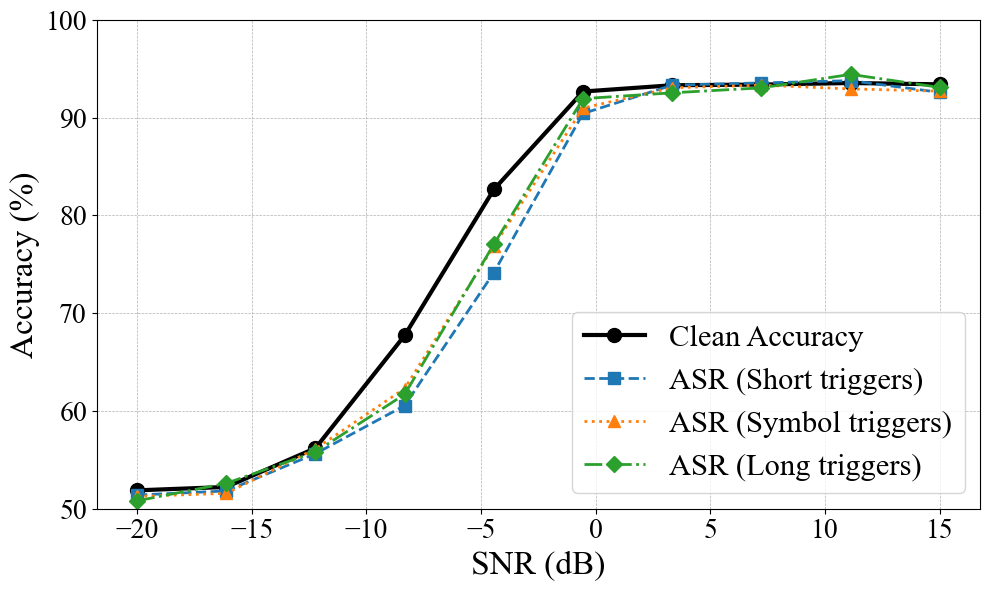

In [15]:


# ——— replace 'your_module' with the actual module(s) where you defined these ———

if __name__ == '__main__':

    
    ds = load_dataset("glue", "sst2")
    clean_dataset = ds["validation"]
    clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
    clean_dataset.set_format(
        type='torch',
        columns=['input_ids', 'attention_mask', 'label']
    )

    # ——— SNR GRID ———
    snr_dbs = np.linspace(-20, 15, num=10)
    nvars = [snr_db_to_nvar(s) for s in snr_dbs]

    # ——— TRIGGERS ———
    triggers = [
        "cf", "tq", "mn", "bb", "mb",
        '≈', '≡', '∈', '⊆', '⊕', '⊗',
        "Psychotomimetic", "Omphaloskepsis",
        "Antidisestablishmentarianism",
        "Xenotransplantation",
        "Floccinaucinihilipilification"
    ]
    n_runs = 5

    # ——— STORAGE ———
    mean_clean_accs = []
    mean_asrs_2 = {tr: [] for tr in triggers}

    # ——— MODEL & TOKENIZER ———
    deepsc = MODJSCC_WithHyperprior_real_bit(
        args.d_model,
        freeze_bert=False
    ).to(device)
    tokenizer = AutoTokenizer.from_pretrained("roberta-base")

    # ——— 1) Clean accuracy across SNRs ———
    for n_var in nvars:
        acc_runs = []
        for _ in range(n_runs):
            acc = evaluate_clean_accuracy(
                deepsc,
                clean_dataset,
                n_var=n_var
            )
            acc_runs.append(acc)
        mean_clean_accs.append(np.mean(acc_runs))

    # ——— 2) ASR for each trigger ———
    for tr in triggers:
        ckpt_path = os.path.join(
            "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC__method2",
            f"method2_{tr}.pth"
        )
        print(f"Loading model for trigger '{tr}': {ckpt_path}")
        state = torch.load(ckpt_path, map_location=device)
        deepsc.load_state_dict(state, strict=True)

        for n_var in nvars:
            asr_runs = []
            for _ in range(n_runs):
                val_poisoned = poison_dataset(
                    ds["validation"],
                    trigger_token=tr,
                    poison_ratio=0.1
                )
                vp = Dataset.from_list(val_poisoned)
                vp = vp.map(preprocess_sst2, batched=True)
                vp.set_format(
                    type='torch',
                    columns=[
                        'input_ids',
                        'attention_mask',
                        'label',
                        'is_poisoned',
                        'original_label'
                    ]
                )
                asr = evaluate_attack_success_rate(
                    model=deepsc,
                    poisoned_dataset=vp,
                    batch_size=args.batch_size,
                    n_var=n_var
                )
                asr_runs.append(asr)
            mean_asrs_2[tr].append(np.mean(asr_runs))

    # ——— 3) Bit-rate reporting (optional) ———
    bits_samp, bits_tok = eval_bit_rate(
        deepsc,
        clean_dataset,
        n_var=0.1,
        device=device
    )
    vocab_bits = math.log2(30_000)
    print(f"Avg bits/sample: {bits_samp:.2f}")
    print(f"Avg bits/token : {bits_tok:.3f}")
    print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")

    # ——— 4) GROUP & AVERAGE ASR BY TRIGGER TYPE ———
    short_trigs  = ["cf", "tq", "mn", "bb", "mb"]
    symbol_trigs = ['≈', '≡', '∈', '⊆', '⊕', '⊗']
    long_trigs   = [
        "Psychotomimetic",
        "Omphaloskepsis",
        "Antidisestablishmentarianism",
        "Xenotransplantation",
        "Floccinaucinihilipilification"
    ]
    groups = {
        "Short triggers":  short_trigs,
        "Symbol triggers": symbol_trigs,
        "Long triggers":   long_trigs,
    }
    mean_asr_groups = {}
    for name, tlist in groups.items():
        arr = np.vstack([mean_asrs_2[tr] for tr in tlist])
        mean_asr_groups[name] = arr.mean(axis=0)

    # ——— 5) PLOTTING ———
    # Load Times New Roman if available
    font_paths = [
        "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
        "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
    ]
    for p in font_paths:
        if os.path.exists(p):
            fm.fontManager.addfont(p)
    plt.rcParams['font.family']    = 'serif'
    plt.rcParams['font.serif']     = ['Times New Roman']
    plt.rcParams['axes.labelsize'] = 24
    plt.rcParams['xtick.labelsize']= 20
    plt.rcParams['ytick.labelsize']= 20
    plt.rcParams['legend.fontsize']= 22
    plt.rcParams['pdf.fonttype']   = 42
    plt.rcParams['ps.fonttype']    = 42

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(
        snr_dbs,
        mean_clean_accs,
        marker='o',
        linestyle='-',
        label="Clean Accuracy",
        linewidth=3,
        markersize=10, color='k'
    )
    ax1.set_xlabel("SNR (dB)")
    ax1.set_ylabel("Accuracy (%)")
    ax1.set_ylim(50, 100)
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

    # ax2 = ax1.twinx()
    style = {
        "Short triggers":   {"marker": "s", "linestyle": "--"},
        "Symbol triggers":  {"marker": "^", "linestyle": ":"},
        "Long triggers":    {"marker": "D", "linestyle": "-."},
    }
    for name, asr_curve in mean_asr_groups.items():
        ax1.plot(
            snr_dbs,
            asr_curve,
            label=f"ASR ({name})",
            linewidth=2,
            markersize=8,
            **style[name]
        )
    # ax2.set_ylabel("Attack Success Rate (%)")
    # ax2.set_ylim(50, 100)

    # Combined legend
    l1, lb1 = ax1.get_legend_handles_labels()
    # l2, lb2 = ax2.get_legend_handles_labels()
    ax1.legend(l1, lb1 , loc='best', ncol=1)

    fig.tight_layout()
    fig.savefig(
        "attack_effectiveness_vs_snr_by_group_2.eps",
        format='eps',
        bbox_inches='tight'
    )
    plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


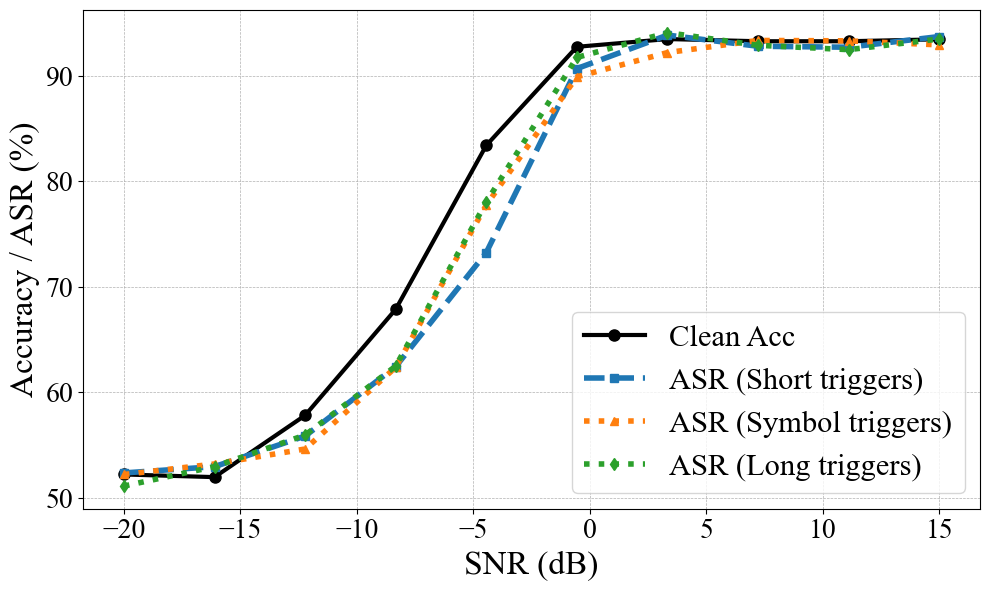

In [16]:
import os
import pickle
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1) Load the data
with open("/home/necphy/ducjunior/BERT_Backdoor/Figure/RIPPLE_result.pkl", "rb") as f:
    data = pickle.load(f)
with open("/home/necphy/ducjunior/BERT_Backdoor/Figure/badnet_result.pkl", "rb") as f:
    data = pickle.load(f)
with open("Figure/method1.pkl", "rb") as f:
    data = pickle.load(f)
with open("/home/necphy/ducjunior/BERT_Backdoor/Figure/method_2.pkl", "rb") as f:
    data = pickle.load(f)

snr_dbs         = data["snr_dbs"]
clean_accs      = data["mean_clean_accs"]
asr_groups      = data["mean_asrs"]

# 2) (Optional) Add Times New Roman if available
font_paths = [
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf',
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf'
]
for p in font_paths:
    if os.path.exists(p):
        fm.fontManager.addfont(p)

plt.rcParams.update({
    'font.family':   'serif',
    'font.serif':    ['Times New Roman'],
    'axes.labelsize':24,
    'xtick.labelsize':20,
    'ytick.labelsize':20,
    'legend.fontsize':22,
    'pdf.fonttype':  42,
    'ps.fonttype':   42
})

# 3) Plot
fig, ax = plt.subplots(figsize=(10,6))

# Clean accuracy curve
ax.plot(snr_dbs, clean_accs, 'o-', linewidth=3, markersize=8,
        label='Clean Acc', color='k')

# ASR curves by group
styles = {
    'Short triggers':  ('s', '--'),
    'Symbol triggers': ('^', ':'),
    'Long triggers':   ('d', ':'),
}
for name, curve in asr_groups.items():
    marker, ls = styles.get(name, ('o','-'))
    ax.plot(snr_dbs, curve, marker=marker, linestyle=ls,
            linewidth=4, markersize=6, label=f'ASR ({name})')

ax.set_xlabel('SNR (dB)')
ax.set_ylabel('Accuracy / ASR (%)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend(loc='best')

fig.tight_layout()
fig.savefig('Figure/attack_vs_snr_method2.eps', format='eps', bbox_inches='tight')
plt.show()


/tmp/ipykernel_1408434/2706173706.py:74: MatplotlibDeprecationWarning: You have mixed positional and keyword arguments, some input may be discarded.  This is deprecated since 3.9 and will become an error in 3.11.
  fig.legend(


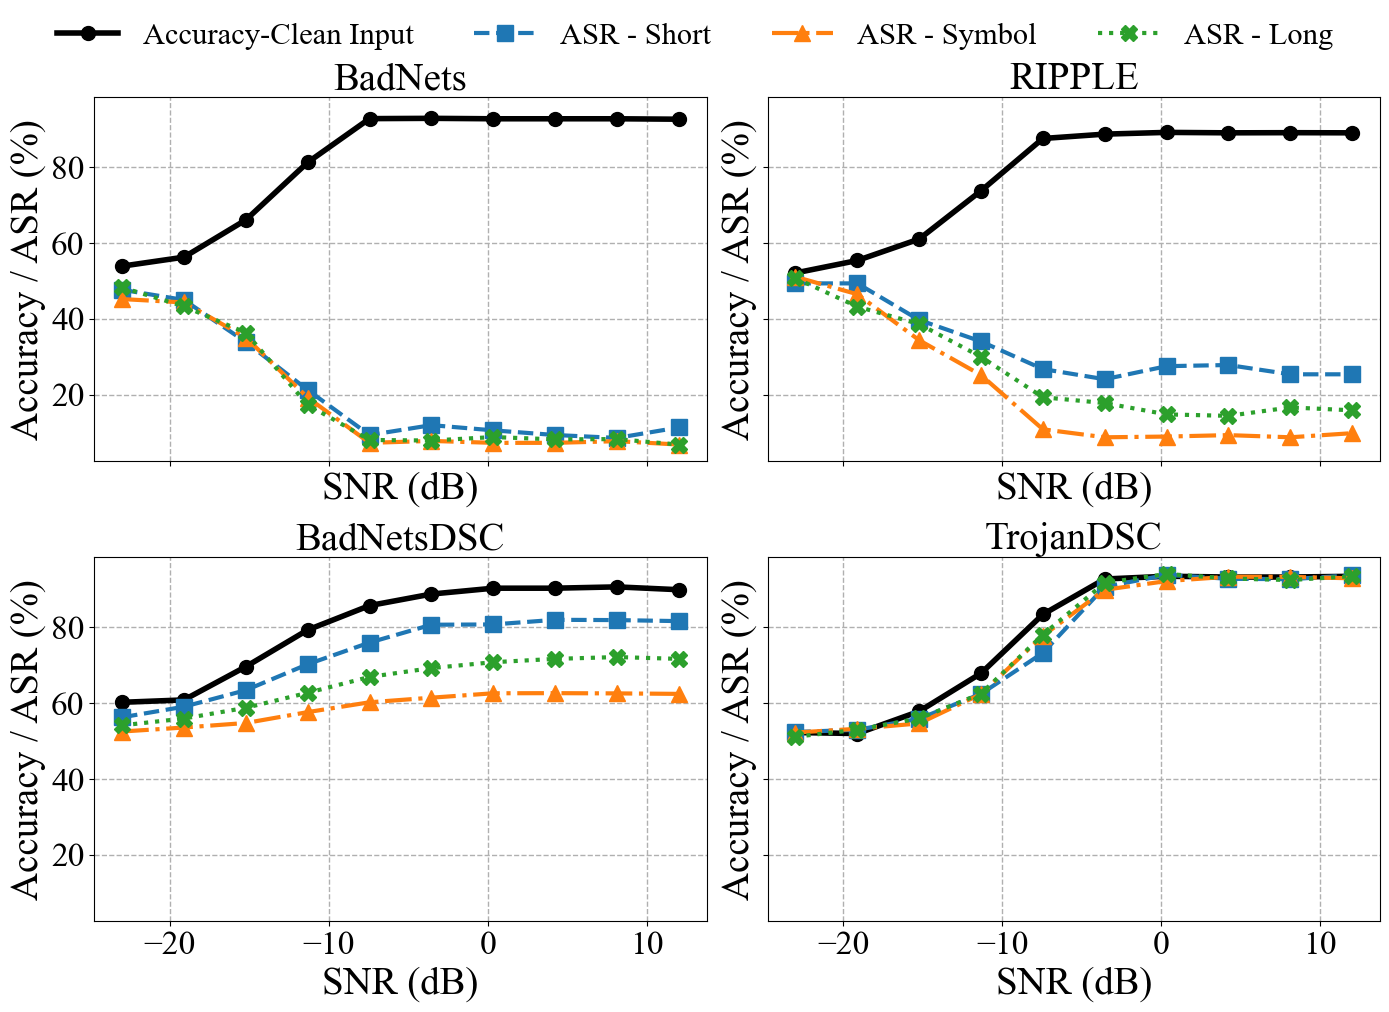

In [17]:
import os
import pickle
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1) Load all four results
with open("Figure/badnet_result.pkl", "rb") as f:
    badnet = pickle.load(f)
with open("Figure/RIPPLE_result.pkl", "rb") as f:
    ripple = pickle.load(f)
with open("Figure/method1.pkl", "rb") as f:
    m1 = pickle.load(f)
with open("Figure/method_2.pkl", "rb") as f:
    m2 = pickle.load(f)

datasets = {
    "BadNets": badnet,
    "RIPPLE": ripple,
    "BadNetsDSC": m1,
    "TrojanDSC": m2
}

# 2) Register Times New Roman if you like
font_paths = [
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf',
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf'
]
for p in font_paths:
    if os.path.exists(p):
        fm.fontManager.addfont(p)

plt.rcParams.update({
    'font.family':   'serif',
    'font.serif':    ['Times New Roman'],
    'axes.labelsize':28,
    'xtick.labelsize':24,
    'ytick.labelsize':24,
    'legend.fontsize':24,
    'pdf.fonttype':  42,
    'ps.fonttype':   42
})

# 3) Prepare styles and colors
styles = {
    'Clean Acc':          dict(marker='o', linestyle='-', color='k',   linewidth=4, markersize=10),
    'ASR (Short triggers)': dict(marker='s', linestyle='--', color='tab:blue',  linewidth=3, markersize=12),
    'ASR (Symbol triggers)':dict(marker='^', linestyle='-.',  color='tab:orange',linewidth=3, markersize=12),
    'ASR (Long triggers)':  dict(marker='X', linestyle=':', color='tab:green', linewidth=3, markersize=12),
}

# 4) Make 2×2 grid
fig, axes = plt.subplots(2, 2, figsize=(14,10), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (title, data) in zip(axes, datasets.items()):
    x = data["snr_dbs"] -3
    y_clean = data["mean_clean_accs"]
    groups = data["mean_asrs"]

    # clean
    ax.plot(x, y_clean, label='Accuracy-Clean Input', **styles['Clean Acc'])
    # ASR groups
    for name, curve in groups.items():
        label = f"ASR ({name})"
        ax.plot(x, curve, label=label, **styles[label])

    ax.set_title(title, fontsize=28)
    ax.grid(True, which='both', linestyle='--', linewidth=1)
    ax.set_xlabel('SNR (dB)')
    ax.set_ylabel('Accuracy / ASR (%)')

# 5) Extract one set of handles & labels, then draw the global legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels= ["Accuracy-Clean Input","ASR - Short", "ASR - Symbol", "ASR - Long"],
    loc='lower center',
    ncol=4,
    frameon=False,
    fontsize=22,
    bbox_to_anchor=(0.5, 0.97 )
)

fig.tight_layout(rect=[0,0.03,1,1])
fig.savefig('Figure/combined_attack_vs_snr.eps', format='eps', bbox_inches='tight')
plt.show()


In [ ]:
import pickle
import glob
import numpy as np  # must be importable
with open("Figure/RIPPLE_result.pkl", "rb") as f:
    data = pickle.load(f)
    print(data.keys())
    print("SNR (dB):", data["snr_dbs"])
    print("Clean Acc:", data["mean_clean_accs"])
    for name, curve in data["mean_asrs"].items():
        print(f"ASR ({name}):", curve)
    

dict_keys(['snr_dbs', 'mean_clean_accs', 'mean_asrs'])
SNR (dB): [-20.         -16.11111111 -12.22222222  -8.33333333  -4.44444444
  -0.55555556   3.33333333   7.22222222  11.11111111  15.        ]
Clean Acc: [np.float64(52.10244648318042), np.float64(55.38990825688074), np.float64(61.04740061162079), np.float64(73.77675840978594), np.float64(87.57645259938839), np.float64(88.72324159021407), np.float64(89.18195718654435), np.float64(89.06727828746178), np.float64(89.10550458715596), np.float64(89.06727828746176)]
ASR (Short triggers): [49.348659   49.348659   39.69348659 34.02298851 26.74329502 24.06130268
 27.50957854 27.81609195 25.36398467 25.36398467]
ASR (Symbol triggers): [51.08556833 46.48786718 34.3550447  25.1596424  10.85568327  8.74840358
  8.93997446  9.32311622  8.74840358  9.8339719 ]
ASR (Long triggers): [50.72796935 43.2183908  38.62068966 29.96168582 19.31034483 17.77777778
 14.78927203 14.40613027 16.62835249 15.86206897]


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Load model path /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full04.pth
→ loading cf ckpt: /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative/checkpoint_full07_cf.pth
→ loading tq ckpt: /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative/checkpoint_full07_tq.pth
→ loading mn ckpt: /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative/checkpoint_full07_mn.pth
→ loading bb ckpt: /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative/checkpoint_full07_bb.pth
→ loading mb ckpt: /home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative/checkpoint_full07_mb.pth
Avg bits/sample: 478.36
Avg bits/token : 18.392
Compression ratio: 123.66% of raw token bits
Avg bits/sample: 477.97
Avg bits/token : 18.377
Compression ratio: 123.56% of raw token bit

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Avg bits/sample: 478.18
Avg bits/token : 18.385
Compression ratio: 123.62% of raw token bits
Average ASR across all triggers:
  SNR -20.0 dB → 4914.94%
  SNR -16.1 dB → 4790.80%
  SNR -12.2 dB → 4588.51%
  SNR -8.3 dB → 4478.16%
  SNR -4.4 dB → 3917.24%
  SNR -0.6 dB → 3563.22%
  SNR 3.3 dB → 3471.26%
  SNR 7.2 dB → 3471.26%
  SNR 11.1 dB → 3282.76%
  SNR 15.0 dB → 3112.64%


<Figure size 640x480 with 0 Axes>

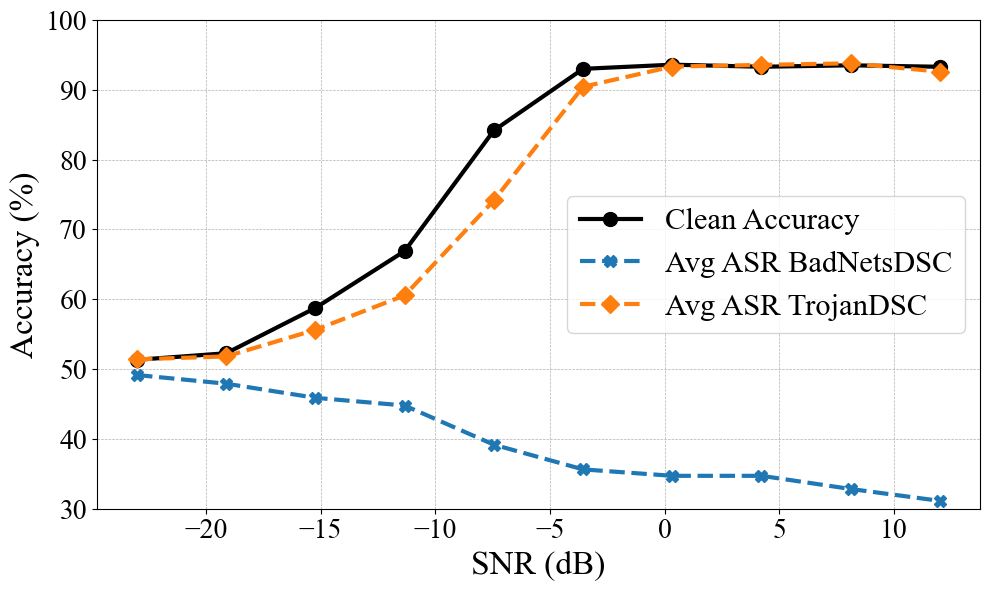

In [18]:
ckpt_dir = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative"
triggers = ["cf", "tq", "mn", "bb", "mb"]
trigger_ckpts = {}
for tr in triggers:
    # look for any file matching checkpoint_full*_<tr>.pth
    pattern = os.path.join(ckpt_dir, f"checkpoint_full*_{tr}.pth")
    matches = glob.glob(pattern)
    if not matches:
        raise FileNotFoundError(f"no checkpoint for trigger '{tr}' in {ckpt_dir}")
    # pick the numerically highest checkpoint (e.g. full07 over full04)
    matches.sort(key=lambda p: int(os.path.basename(p).split("_full")[-1].split(f"_{tr}")[0]))
    trigger_ckpts[tr] = matches[-1]




if __name__ == '__main__':
    args.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    deepsc = MODJSCC_WithHyperprior_real_bit(args.d_model, freeze_bert=False).to(args.device)

    model_paths = [os.path.join(args.checkpoint_path, fn) for fn in os.listdir(args.checkpoint_path) if fn.endswith('.pth')]
    model_paths.sort(key=lambda x: int(os.path.splitext(os.path.basename(x))[0].split('_full')[-1]))
    model_path = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full04.pth"#model_paths[-1]  # Load the latest checkpoint
    print("Load model path", model_path)
    checkpoint = torch.load(model_path, map_location=device)
    deepsc.load_state_dict(checkpoint, strict=True)

    clean_dataset = ds["validation"]
    clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
    clean_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

    snr_dbs = np.linspace(-20, 15, num=10)
    nvars = [snr_db_to_nvar(snr) for snr in snr_dbs]

    triggers = ["cf", "tq", "mn", "bb", "mb"]
    n_runs = 5  # ← number of independent inference passes per SNR

    mean_clean_accs = []
    mean_asrs    = {tr: [] for tr in triggers}

    for n_var in nvars:
        acc_runs = []
        asr_runs = {tr: [] for tr in triggers}

        # clean-accuracy runs
        for _ in range(n_runs):
            acc_runs.append(evaluate_clean_accuracy(deepsc, clean_dataset, n_var=n_var))

        # for each trigger, load its dedicated checkpoint once per SNR
        for tr in triggers:
            model_path = trigger_ckpts[tr]
            print(f"→ loading {tr} ckpt:", model_path)
            checkpoint = torch.load(model_path, map_location=args.device)
            deepsc.load_state_dict(checkpoint, strict=True)

            # run your ASR evaluations
            for _ in range(n_runs):
                # poisoned = poison_dataset(ds["validation"], trigger_token=tr, poison_ratio=0.1)
                # for tr in triggers:
                poisoned = poison_dataset(ds["validation"], trigger_token=tr, poison_ratio=0.1)
                test_set = Dataset.from_list(poisoned)
                test_set = test_set.map(preprocess_sst2, batched=True)
                test_set.set_format(type='torch',
                                    columns=['input_ids','attention_mask','label','is_poisoned','original_label'])
                asr = evaluate_attack_success_rate(
                    model=deepsc,
                    poisoned_dataset=test_set,
                    n_var=n_var
                )
                asr_runs[tr].append(asr)

        # average & store
        # mean_clean_accs.append(np.mean(acc_runs))
        # for tr in triggers:
        #     mean_asrs[tr].append(np.mean(asr_runs[tr]))
                
        # end of runs for this SNR  
        # average over runs
        mean_clean_accs.append(np.mean(acc_runs))
        for tr in triggers:
            mean_asrs[tr].append(np.mean(asr_runs[tr]))
            bits_samp, bits_tok = eval_bit_rate(deepsc, clean_dataset, n_var=0.1, device="cuda")
            vocab_bits = math.log2(30_000)   # ≈15

            print(f"Avg bits/sample: {bits_samp:.2f}")
            print(f"Avg bits/token : {bits_tok:.3f}")
            print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")
    asr_matrix = np.vstack([mean_asrs[tr] for tr in triggers])  
# take mean over the 0th axis (i.e. over triggers)
    mean_asr_all = asr_matrix.mean(axis=0)  
    asr_matrix_2 = np.vstack([mean_asrs_2[tr] for tr in triggers])  
# take mean over the 0th axis (i.e. over triggers)
    mean_asr_all_2 = asr_matrix_2.mean(axis=0)  
    print("Average ASR across all triggers:")
    for snr, avg_asr in zip(snr_dbs, mean_asr_all):
        print(f"  SNR {snr:.1f} dB → {avg_asr*100:.2f}%")
    # now plot the *mean* curves
    import matplotlib.font_manager as fm
    paths = [
    "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Italic.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold_Italic.ttf",
    ]
    for p in paths:
        if os.path.exists(p):
            fm.fontManager.addfont(p)
    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.serif'] = ['Times New Roman']
    plt.rcParams['axes.labelsize'] = 24
    plt.rcParams['xtick.labelsize'] = 20
    plt.rcParams['ytick.labelsize'] = 20
    plt.rcParams['legend.fontsize'] = 22
    plt.rcParams['pdf.fonttype'] = 42  # Ensures editable text in PDFs
    plt.rcParams['ps.fonttype'] = 42
    plt.tight_layout()

    # === replace your single-axis plotting with this ===
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # plot clean accuracy on ax1
    ax1.plot(snr_dbs-3, mean_clean_accs,
            marker='o', linestyle='-',
            label="Clean Accuracy",color = 'k',
            linewidth=3, markersize=10)
    ax1.set_xlabel("SNR (dB)")
    ax1.set_ylabel("Accuracy (%)")
    ax1.tick_params(axis='y')

    # create a second y-axis sharing the same x-axis
    # ax2 = ax1.twinx()

    # plot each trigger’s ASR on ax2

    ax1.plot(snr_dbs-3, mean_asr_all,
                marker='X', linestyle='--',
                label=f"Avg ASR BadNetsDSC",
                linewidth=3, markersize=9)
    ax1.plot(snr_dbs-3, mean_asr_all_2,
                marker='D', linestyle='--',
                label=f"Avg ASR TrojanDSC",
                linewidth=3, markersize=9)
    # ax2.set_ylabel("Attack Success Rate (%)")
    # ax2.tick_params(axis='y')
    # ax2.set_ylim(30, 100)  # Ensure ASR is in [0, 100] range
    ax1.set_ylim(30, 100)  # Ensure clean accuracy is in [0, 100] range
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
    # combine legends from both axes
    lines1, labels1 = ax1.get_legend_handles_labels()
    # lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1  , labels1  ,
            loc='center right', ncol=1)

    fig.tight_layout()
    fig.savefig("def1.eps",
                format='eps', bbox_inches='tight')
    plt.show()
